In [38]:
import pandas as pd
import matplotlib.pyplot as plt
import scipy.stats as tests
# titles = [
#     "Oppenheimer",
#     "Barbie",
#     "Dune: Part Two",
#     "Madame Web",
#     "Inside Out 2",
#     "The Odyssey",
#     "Spider-Man: Brand New Day",
#     "Hoppers",
#     "Toy Story 5",
#     "The Emoji Movie",
#     "The Human Centipede"
# ]

titles = [
    "Oppenheimer",
    "Barbie",
    "Dune: Part Two",
    "Madame Web",
    "Inside Out 2",
    "The Odyssey",
    "Spider-Man: Brand New Day",
    "Hoppers",
    "Toy Story 5",
    "The Emoji Movie",
    "The Human Centipede",
    "Parasite",
    "Everything Everywhere All at Once",
    "Spider-Man: Into the Spider-Verse",
    "Mad Max: Fury Road",
    "Get Out",
    "Whiplash",
    "Top Gun: Maverick",
    "Jurassic World",
    "Guardians of the Galaxy Vol. 3",
    "Wonka",
    "Wicked",
    "Avatar: The Way of Water",
    "Black Adam",
    "Thor: Love and Thunder",
    "Ant-Man and the Wasp: Quantumania",
    "Aquaman",
    "Ready Player One",
    "The Hunger Games: The Ballad of Songbirds & Snakes",
    "Fast X",
    "Justice League",
    "Batman v Superman: Dawn of Justice",
    "Suicide Squad",
    "Venom",
    "Transformers: Age of Extinction",
    "Cats",
    "The Last Airbender",
    "Morbius",
    "Fantastic Four",
    "Dolittle",
    "Jupiter Ascending",
]

movies = pd.DataFrame({"title": titles})
display(movies)

,title
0,Oppenheimer
1,Barbie
2,Dune: Part Two
3,Madame Web
4,Inside Out 2
5,The Odyssey
6,Spider-Man: Brand New Day
7,Hoppers
8,Toy Story 5
9,The Emoji Movie


In [39]:
import requests

OMDB_KEY = "690401ba"

def get_movie(title):
    response = requests.get(
        "https://www.omdbapi.com/",
        params={"apikey": OMDB_KEY, "t": title},
    )
    data = response.json()

    if data.get("Response") != "True":
        print("Not found:", title)
        return None

    rt = next(
        (r["Value"] for r in data.get("Ratings", [])
         if r["Source"] == "Rotten Tomatoes"),
        None
    )

    return {
        "title": data["Title"],
        "imdb_id": data["imdbID"],
        "release_date": data.get("Released"),
        "genre": data.get("Genre"),
        "rt_score": int(rt.rstrip("%")) if rt else None
    }

records = [get_movie(title) for title in titles]

movies = pd.DataFrame(
    [record for record in records if record is not None]
)

movies["release_date"] = pd.to_datetime(
    movies["release_date"]
)

movies = movies.dropna(subset=["rt_score", "release_date"]).drop_duplicates("imdb_id")
movies.to_csv("data/movies.csv", index=False)
print("Movies kept:", len(movies))

display(movies)

Movies kept: 41


,title,imdb_id,release_date,genre,rt_score
0,Oppenheimer,tt15398776,2023-07-21,"Biography, Drama, History",93
1,Barbie,tt1517268,2023-07-21,"Adventure, Comedy, Fantasy",88
2,Dune: Part Two,tt15239678,2024-03-01,"Action, Adventure, Drama",92
3,Madame Web,tt11057302,2024-02-14,"Action, Thriller",10
4,Inside Out 2,tt22022452,2024-06-14,"Animation, Adventure, Comedy",91
5,The Odyssey,tt33764258,2026-07-17,"Action, Adventure, Fantasy",94
6,Spider-Man: Brand New Day,tt22084616,2026-07-31,"Action, Adventure",90
7,Hoppers,tt26443616,2026-03-06,"Animation, Adventure, Comedy",94
8,Toy Story 5,tt29355505,2026-06-19,"Animation, Adventure, Comedy",92
9,The Emoji Movie,tt4877122,2017-07-28,"Animation, Adventure, Comedy",6


In [40]:
from datetime import timedelta
import time

ARCTIC_URL = (
    "https://arctic-shift.photon-reddit.com/api/posts/search"
)

def fetch_posts(title, release_date, subreddit):
    release = pd.Timestamp(release_date)

    end = release - pd.Timedelta(days=3)
    start = end - pd.Timedelta(days=30)

    params = {
        "subreddit": subreddit,
        "title": title,
        "after": start.strftime("%Y-%m-%d"),
        "before": end.strftime("%Y-%m-%d"),
        "limit": 100,
        "sort": "asc",
        "fields": (
            "id,title,subreddit,score,"
            "num_comments,created_utc,selftext"
        )
    }

    response = requests.get(ARCTIC_URL,params=params, timeout=60)
    response.raise_for_status()

    return response.json().get("data", [])  

In [41]:
all_posts = []
failures = []

movies = pd.read_csv("data/movies.csv", parse_dates=["release_date"])

for _, movie in movies.iterrows():
    for subreddit in ["movies", "boxoffice"]:
        try:
            results = fetch_posts(
                movie["title"],
                movie["release_date"],
                subreddit
            )

            for post in results:
                post["movie_id"] = movie["imdb_id"]
                post["movie_title"] = movie["title"]

            all_posts.extend(results)

        except requests.RequestException as e:
            failures.append({
                "movie": movie["title"],
                "subreddit": subreddit,
                "error": str(e)
            })

        time.sleep(1)

posts_df = pd.DataFrame(all_posts)

print("Posts collected:", len(posts_df))
print("Failed searches:", len(failures))

display(posts_df.head())
display(pd.DataFrame(failures))

Posts collected: 429
Failed searches: 71


,created_utc,id,num_comments,score,selftext,subreddit,title,movie_id,movie_title
0,1687181599,14detd9,33,128,,boxoffice,M37: “4m+ previews for Oppenheimer pretty much...,tt15398776,Oppenheimer
1,1687196284,14dl4u8,166,265,,boxoffice,[keysersoze on BOT] Oppenheimer tracking is lo...,tt15398776,Oppenheimer
2,1687306925,14es6zk,0,1,\n\n[View Poll](https://www.reddit.com/poll/14...,boxoffice,Which film would win at the box office? Oppenh...,tt15398776,Oppenheimer
3,1687378268,14fi04f,16,35,,boxoffice,[keysersoze on Oppenheimer's presales] I can a...,tt15398776,Oppenheimer
4,1687468791,14gfea0,165,277,,boxoffice,"For some positivity today, Barbie Movie sales ...",tt15398776,Oppenheimer


,movie,subreddit,error
0,Oppenheimer,movies,422 Client Error: Unprocessable Entity for url...
1,Barbie,movies,422 Client Error: Unprocessable Entity for url...
2,Barbie,boxoffice,422 Client Error: Unprocessable Entity for url...
3,Dune: Part Two,movies,422 Client Error: Unprocessable Entity for url...
4,Madame Web,movies,422 Client Error: Unprocessable Entity for url...
...,...,...,...
66,Fantastic Four,boxoffice,429 Client Error: Too Many Requests for url: h...
67,Dolittle,movies,429 Client Error: Too Many Requests for url: h...
68,Dolittle,boxoffice,429 Client Error: Too Many Requests for url: h...
69,Jupiter Ascending,movies,429 Client Error: Too Many Requests for url: h...


In [42]:
posts_df = posts_df.drop_duplicates(subset=["movie_id", "id"])
posts_df["score"] = pd.to_numeric(posts_df["score"])
posts_df["num_comments"] = pd.to_numeric(posts_df["num_comments"],)
posts_df["created_utc"] = pd.to_datetime(posts_df["created_utc"], unit="s", utc=True,)
posts_df = posts_df.dropna(subset=["movie_id", "id", "created_utc"])

posts_df.to_csv("data/reddit_posts.csv", index=False)

In [43]:
movie_stats = (
    posts_df.groupby("movie_id")
    .agg(
        total_posts=("id", "count"),
        total_comments=("num_comments", "sum"),
        avg_post_score=("score", "mean"),
        median_post_score=("score", "median"),
        max_post_score=("score", "max"),
        subreddit_count=("subreddit", "nunique")
    )
    .reset_index()
)

movie_features = movies.merge(
    movie_stats,
    left_on="imdb_id",
    right_on="movie_id",
    how="left"
)

movie_features["total_posts"] = (movie_features["total_posts"].fillna(0))
movie_features.to_csv("data/movie_features.csv",)

display(movie_features.head())

,title,imdb_id,release_date,genre,rt_score,movie_id,total_posts,total_comments,avg_post_score,median_post_score,max_post_score,subreddit_count
0,Oppenheimer,tt15398776,2023-07-21,"Biography, Drama, History",93,tt15398776,100.0,5728.0,115.460000,20.5,1605.0,1.0
1,Barbie,tt1517268,2023-07-21,"Adventure, Comedy, Fantasy",88,NaN,0.0,NaN,NaN,NaN,NaN,NaN
2,Dune: Part Two,tt15239678,2024-03-01,"Action, Adventure, Drama",92,tt15239678,19.0,1492.0,191.736842,16.0,1058.0,1.0
3,Madame Web,tt11057302,2024-02-14,"Action, Thriller",10,tt11057302,36.0,1687.0,98.583333,14.0,677.0,1.0
4,Inside Out 2,tt22022452,2024-06-14,"Animation, Adventure, Comedy",91,NaN,0.0,NaN,NaN,NaN,NaN,NaN


In [44]:
posts_df.shape

(429, 9)

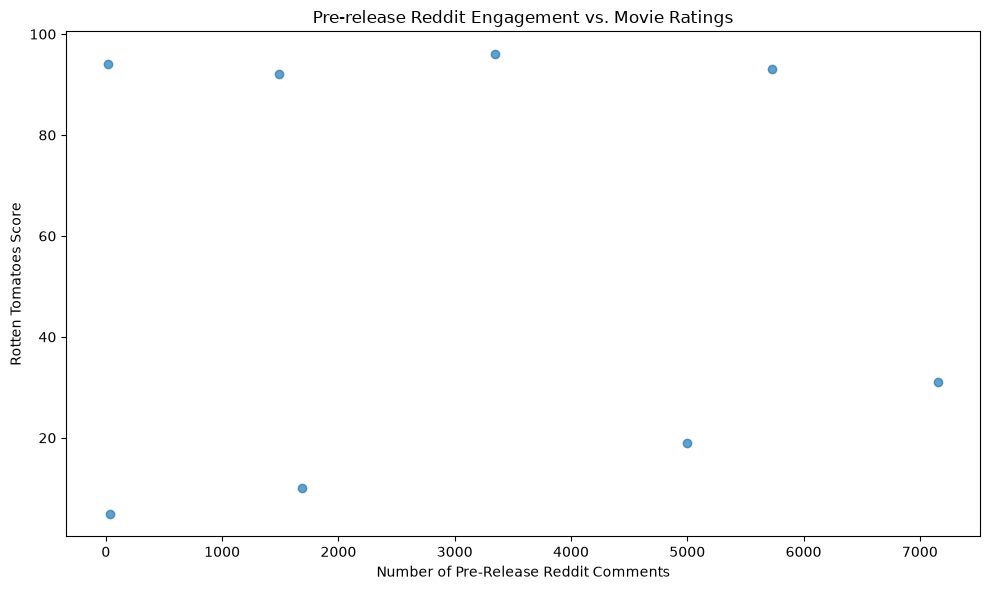

Upon applying Spearman's Rank Correlation we find that the p-value is:  0.9108491685195836 and the correlation is:  0.04761904761904763


In [ ]:
# Question - Is Reddit engagement prior to a movies release correlated with the Rotten Tomatoes score 
# of a movie? (tracked as the amount of total comments on posts about a given movie)
# To answer this question, we will present the following hypothesis: 
# Hypothesis - There is a correlation between the amount pre-release Reddit comments about a movie and 
# the Rotten Tomatoes score of that movie.
# Null Hypothesis - There is no correlation between the amount pre-release Reddit comments about a movie 
# and the Rotten Tomatoes score of that movie.

graph_data = movie_features[["total_comments", "rt_score"]].dropna()
plt.figure(figsize=(10, 6))
x = graph_data["total_comments"]
y = graph_data["rt_score"]
plt.scatter(x, y, alpha=0.7)
plt.xlabel("Number of Pre-Release Reddit Comments")
plt.ylabel("Rotten Tomatoes Score")
plt.title("Pre-release Reddit Engagement vs. Movie Ratings")
plt.tight_layout()
plt.show()
# GORGEOUS graph

r, p = tests.spearmanr(x, y)
print("Upon applying Spearman's Rank Correlation we find that the p-value is: ", p, "and the correlation is: ", r)

# Sometimes the data is inconsistent due to rate limiting, but across multiple tests 
